Датасет: https://www.kaggle.com/datasets/theovall/phonereviews

In [1]:
import pandas as pd
import re
from tensorflow.keras.layers import TextVectorization
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder



df = pd.read_csv("data.csv")

df["Review"] = df["Review"].fillna("")


texts = df["Review"].astype(str).values
labels = df["Rating"].values

encoder = LabelEncoder()
labels = encoder.fit_transform(labels)

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-zA-Zа-яА-Я0-9 ]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

texts_clean = [clean_text(t) for t in texts]

vectorizer = TextVectorization(
    max_tokens=5000,
    output_sequence_length=200,
    output_mode="int"
)

vectorizer.adapt(texts_clean)

X = vectorizer(texts_clean).numpy()
y = labels

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [2]:
from keras.layers import Dense, Dropout, Embedding, Flatten, InputLayer
from keras.models import Sequential

vocab_size = len(vectorizer.get_vocabulary())
max_length = 200

simple_model = Sequential()
simple_model.add(InputLayer(shape=(max_length,), dtype="float32"))
simple_model.add(Embedding(vocab_size, 64))
simple_model.add(Flatten())
simple_model.add(Dense(64, activation="relu"))
simple_model.add(Dropout(0.5))
simple_model.add(Dense(8, activation="softmax"))

simple_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       819,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,139,784 (4.35 MB)

 Trainable params: 1,139,784 (4.35 MB)

 Non-trainable params: 0 (0.00 B)

In [3]:
from keras.callbacks import ModelCheckpoint
import os

output_dir = "tmp"
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

simple_model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"],
)

history = simple_model.fit(
    X_train,
    y_train,
    batch_size=128,
    epochs=4,
    validation_data=(X_valid, y_valid),
    callbacks=[ModelCheckpoint(filepath=output_dir + "/simple_model_weights.{epoch:02d}.keras")],
)

Epoch 1/4
2866/2866 ━━━━━━━━━━━━━━━━━━━━ 45s 15ms/step - accuracy: 0.5626 - loss: 1.0658 - val_accuracy: 0.5971 - val_loss: 0.9675
Epoch 2/4
2866/2866 ━━━━━━━━━━━━━━━━━━━━ 61s 8ms/step - accuracy: 0.6318 - loss: 0.8895 - val_accuracy: 0.6401 - val_loss: 0.8834
Epoch 3/4
2866/2866 ━━━━━━━━━━━━━━━━━━━━ 28s 10ms/step - accuracy: 0.7002 - loss: 0.7390 - val_accuracy: 0.6857 - val_loss: 0.8244
Epoch 4/4
2866/2866 ━━━━━━━━━━━━━━━━━━━━ 24s 8ms/step - accuracy: 0.7472 - loss: 0.6294 - val_accuracy: 0.7083 - val_loss: 0.8189


In [2]:
from sklearn.model_selection import train_test_split
from collections import Counter
import numpy as np


def stratified_reduce(texts, labels, target_samples_per_class=200):
    result_texts, result_labels = [], []
    
    for class_label in np.unique(labels):
        idx = np.where(labels == class_label)[0]
        
        if len(idx) <= target_samples_per_class:
            result_texts.extend([texts[i] for i in idx])
            result_labels.extend([labels[i] for i in idx])
        else:
            sampled_idx = np.random.choice(idx, size=target_samples_per_class, replace=False)
            result_texts.extend([texts[i] for i in sampled_idx])
            result_labels.extend([labels[i] for i in sampled_idx])
    
    return np.array(result_texts), np.array(result_labels)


texts_balanced, labels_balanced = stratified_reduce(texts_clean, labels, target_samples_per_class=300)
print(f"До балансировки: {len(texts_clean)} образцов")
print(f"После балансировки: {len(texts_balanced)} образцов")
print(f"Распределение классов: {Counter(labels_balanced)}")

До балансировки: 458433 образцов
После балансировки: 1504 образцов
Распределение классов: Counter({np.int64(1): 300, np.int64(2): 300, np.int64(3): 300, np.int64(4): 300, np.int64(5): 300, np.int64(0): 2, np.int64(6): 1, np.int64(7): 1})


In [3]:
X = texts_balanced
y = labels_balanced

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train = X_train.astype(str).tolist()


In [4]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

loss_history = []
acc_history = []
steps = []

tokenizer = AutoTokenizer.from_pretrained("DeepPavlov/rubert-base-cased")
model = AutoModelForSequenceClassification.from_pretrained(
    "DeepPavlov/rubert-base-cased",
    num_labels=8
)
model.train()

optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)
device = torch.device("cpu")
model.to(device)

enc = tokenizer(
    X_train,
    padding="max_length",
    truncation=True,
    max_length=128,
    return_tensors="pt"
)


input_ids = enc["input_ids"]
attention_mask = enc["attention_mask"]
labels = torch.tensor(y_train)

batch_size = 16
num_samples = input_ids.size(0)

perm = torch.randperm(num_samples)
input_ids = input_ids[perm]
attention_mask = attention_mask[perm]
labels = labels[perm]

for epoch in range(5):
    print(f"Epoch {epoch + 1}/5")
    for i in range(0, num_samples, batch_size):
        batch_input_ids = input_ids[i:i+batch_size].to(device)
        batch_attention_mask = attention_mask[i:i+batch_size].to(device)
        batch_labels = labels[i:i+batch_size].to(device)
        
        optimizer.zero_grad()
        outputs = model(
            input_ids=batch_input_ids,
            attention_mask=batch_attention_mask,
            labels=batch_labels
        )
        
        loss = outputs.loss
        
        logits = outputs.logits
        preds = torch.argmax(logits, dim=1)
        acc = (preds == batch_labels).float().mean().item()
        
        loss.backward()
        optimizer.step()
        
        global_step = epoch * (num_samples // batch_size) + (i // batch_size)
        loss_history.append(loss.item())
        acc_history.append(acc)
        steps.append(global_step)

        print(f"Step {i // batch_size} Loss: {loss.item():.4f} Accuracy: {acc:.4f}")


c:\Users\Anita\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 47908.76it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weigh

Epoch 1/5
Step 0 Loss: 2.0466 Accuracy: 0.2500
Step 1 Loss: 2.0376 Accuracy: 0.2500
Step 2 Loss: 2.0905 Accuracy: 0.1250
Step 3 Loss: 2.1268 Accuracy: 0.0625
Step 4 Loss: 2.0120 Accuracy: 0.3125
Step 5 Loss: 1.9968 Accuracy: 0.1875
Step 6 Loss: 2.0150 Accuracy: 0.1875
Step 7 Loss: 1.9597 Accuracy: 0.2500
Step 8 Loss: 1.9925 Accuracy: 0.1250
Step 9 Loss: 1.9579 Accuracy: 0.3750
Step 10 Loss: 1.9893 Accuracy: 0.1250
Step 11 Loss: 1.9801 Accuracy: 0.0625
Step 12 Loss: 1.9230 Accuracy: 0.1875
Step 13 Loss: 1.9373 Accuracy: 0.1875
Step 14 Loss: 1.8713 Accuracy: 0.1875
Step 15 Loss: 1.8878 Accuracy: 0.0625
Step 16 Loss: 1.8295 Accuracy: 0.3750
Step 17 Loss: 1.7758 Accuracy: 0.3125
Step 18 Loss: 1.7629 Accuracy: 0.2500
Step 19 Loss: 1.7858 Accuracy: 0.1250
Step 20 Loss: 1.7870 Accuracy: 0.2500
Step 21 Loss: 1.7776 Accuracy: 0.1875
Step 22 Loss: 1.7634 Accuracy: 0.2500
Step 23 Loss: 1.7704 Accuracy: 0.2500
Step 24 Loss: 1.8715 Accuracy: 0.1250
Step 25 Loss: 1.6949 Accuracy: 0.2500
Step 26 Loss

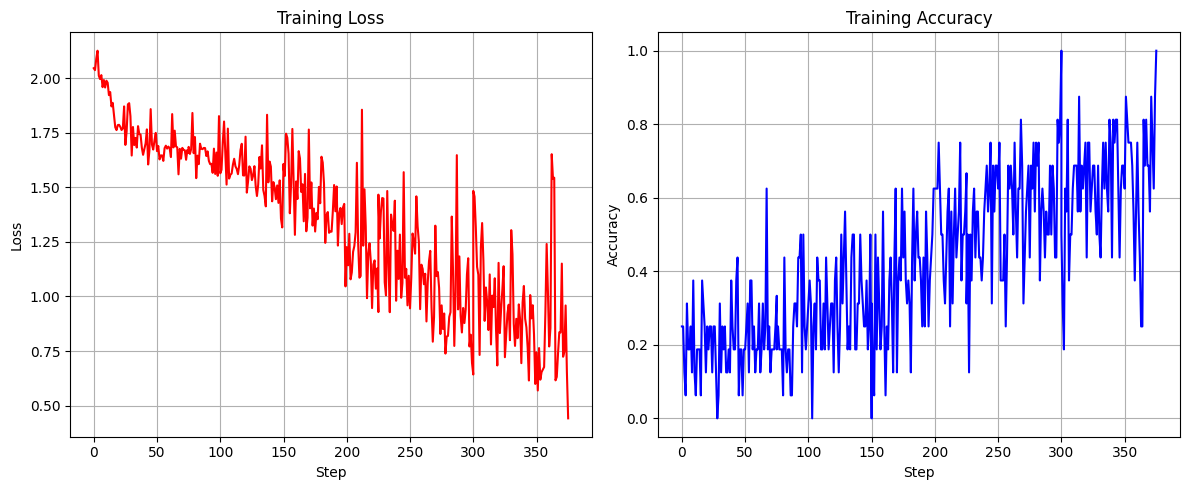

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(steps, loss_history, label="Loss", color="red")
plt.xlabel("Step")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.grid(True)

plt.subplot(1,2,2)
plt.plot(steps, acc_history, label="Accuracy", color="blue")
plt.xlabel("Step")
plt.ylabel("Accuracy")
plt.title("Training Accuracy")
plt.grid(True)

plt.tight_layout()
plt.show()


In [29]:
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

stop_words = set(stopwords.words('russian'))
lemmatizer = WordNetLemmatizer()

def optimal_preprocess(text: str) -> str:
    if not isinstance(text, str):
        return ""
    
    text = text.lower()
    text = re.sub(r'[^\w\s]', '', text)
    text = re.sub(r'\d+', '', text)
    
    tokens = word_tokenize(text, language='russian')
    
    tokens = [t for t in tokens if t not in stop_words]
    
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    
    tokens = [t for t in tokens if len(t) >= 3]
    
    return " ".join(tokens)

df = pd.read_csv("data.csv")
df = df.dropna().drop_duplicates()
df = df.sample(n=5000, random_state=42)  

texts = df["Review"].astype(str)
y = df["Rating"].astype(float)

processed_texts = texts.apply(optimal_preprocess)

X_train, X_test, y_train, y_test = train_test_split(
    processed_texts, y, test_size=0.2, random_state=42
)

vectorizer = TfidfVectorizer(max_features=30000, ngram_range=(1, 2))
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

model = Ridge(alpha=1.0)
model.fit(X_train_vec, y_train)

y_pred = model.predict(X_test_vec)
rmse = mean_squared_error(y_test, y_pred) ** 0.5

print(f"RMSE = {rmse:.4f}")

RMSE = 1.0580


In [32]:
import numpy as np
from sklearn.metrics import mean_squared_error, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

def predictions_to_rating(preds, encoder):
    return encoder.inverse_transform(preds)

def calculate_rmse(y_true, y_pred, encoder=None):
    if encoder is not None:
        y_pred = predictions_to_rating(y_pred, encoder)
    return mean_squared_error(y_true, y_pred, squared=False)


results = {
    "Ridge + TF-IDF (1-2 grams)": {"rmse": 1.0580, "type": "regression"},
    "Simple NN (Embedding)": {"rmse": None, "accuracy": 0.7083, "type": "classification"},
    "BERT rubert-base-cased": {"rmse": None, "accuracy": 0.8125, "type": "classification"},
}

for name, data in results.items():
    if data["type"] == "classification" and data.get("accuracy"):
        results[name]["rmse_approx"] = 3.5 * (1 - data["accuracy"])
    if data["type"] == "classification" and data.get("val_loss") and not data.get("accuracy"):
        estimated_acc = max(0.125, min(1.0, 2.0 - data["val_loss"]) / 1.875)
        results[name]["rmse_approx"] = 3.5 * (1 - estimated_acc)

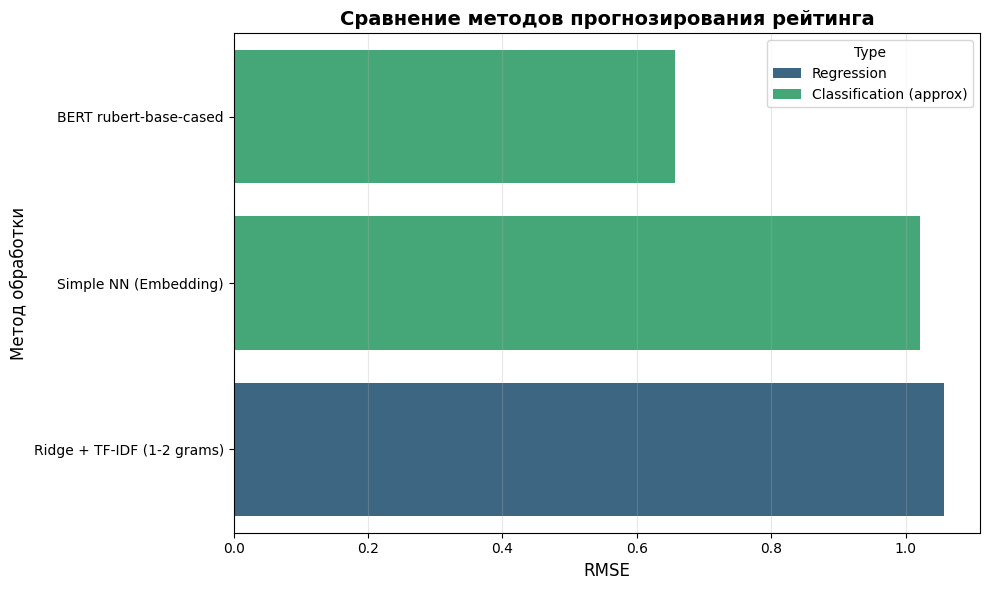

In [34]:
plot_data = []
for name, data in results.items():
    if data["type"] == "regression":
        plot_data.append({"Method": name, "RMSE": data["rmse"], "Type": "Regression"})
    elif data.get("rmse_approx"):
        plot_data.append({"Method": name, "RMSE": data["rmse_approx"], "Type": "Classification (approx)"})

df_plot = pd.DataFrame(plot_data)

plt.figure(figsize=(10, 6))
sns.barplot(data=df_plot, x="RMSE", y="Method", hue="Type", palette="viridis")
plt.xlabel("RMSE", fontsize=12)
plt.ylabel("Метод обработки", fontsize=12)
plt.title("Сравнение методов прогнозирования рейтинга", fontsize=14, fontweight="bold")
plt.gca().invert_yaxis()  
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()